# MVEmo: Attention-based Multimodal Learning untuk Klasifikasi Emosi Musik (Audio + Lirik)

Notebook ini memperluas notebook MoodNet sebelumnya. Pipeline data (manifest, exclusion list, split `tvt_70_15_15`, cache mel dan GloVe) **tidak berubah**, sehingga hasil dapat dibandingkan langsung.

**Yang ditambahkan**

1. **Model usulan `CrossModalMTL`**
   - Encoder audio: CNN 2D pada log-mel menjadi deret token temporal (21 token).
   - Encoder lirik: CNN 1D per baris lirik (GloVe) menjadi deret 100 token baris, dengan padding mask.
   - **Cross-modal attention dua arah**: audio -> lirik (audio sebagai query) dan lirik -> audio (lirik sebagai query), ditumpuk beberapa layer.
   - **Gated fusion** antara representasi audio dan lirik. Nilai gate menjadi sinyal kontribusi modalitas.
   - **Multitask learning**: head emosi (4 quadrant) dan head genre. Loss `L = L_emosi + lambda * L_genre`.
2. **Tiga model deep learning pembanding** (semua audio + lirik, split dan seed sama)
   - Baseline 1: MoodNet-3 (CNN + concatenation, rujukan paper dan hasil terbaik notebook sebelumnya)
   - Baseline 2: CRNN BiGRU dengan late fusion
   - Baseline 3: Joint Transformer dengan early fusion (self-attention saja, tanpa cross-modal attention)
3. **Ablasi**: tanpa MTL dan tanpa cross-attention.
4. **Analisis interpretabilitas**: oklusi modalitas, bobot gate per kelas, dan peta cross-attention.

Alur: muat cache -> label genre -> definisi model -> training (3 seed) -> ringkasan -> interpretabilitas.


In [2]:
import os
import sys
from pathlib import Path

# Kurangi fragmentasi VRAM pada GPU kecil (harus diset sebelum torch/CUDA dipakai).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")


def find_project_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "data" / "merge_bimodal_complete_metadata.csv").exists():
            return cand
    return p


ROOT = find_project_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)


Project root: D:\PELAJARAN\Semester 5\MACHINE LEARNING\Projek\MERGE_Bimodal_Complete


## 0. Dependensi dan prasyarat

Environment proyek ini dikelola dengan `uv`. Dari root proyek jalankan:

```powershell
python -m uv sync
python -m uv run python -m ipykernel install --user --name merge-bimodal --display-name "Python (MERGE Bimodal)"
```

Fitur audio dan lirik diekstrak sekali oleh script terpisah:

```powershell
python -m uv run python scripts/prepare_features.py
```

Script tersebut mendekode MP3 (librosa + soundfile), membuat log-mel, membangun token GloVe, dan menyimpan exclusion list. Notebook ini hanya memuat cache hasil script.


## 1. Konfigurasi


In [3]:
import random
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# ---------- Path ----------
DATA = ROOT / "data"
META_CSV = DATA / "merge_bimodal_complete_metadata.csv"
AUDIO_DIR = DATA / "audio"
LYRICS_DIR = DATA / "lyrics"
SPLIT_NAME = "tvt_70_15_15"
SPLIT_DIR = DATA / "tvt_dataframes" / SPLIT_NAME

PROC = ROOT / "processed"
EXP = ROOT / "experiments"
CKPT = ROOT / "checkpoints"
MEL_DIR = PROC / "mel_spectrograms"
LYRICS_NPZ = PROC / "lyrics_embeddings" / "lyrics_glove_ids.npz"
EXCLUDED_CSV = PROC / "excluded_short_audio.csv"
for d in [PROC, PROC / "splits", EXP / "moodnet", EXP / "attn_mtl", CKPT]:
    d.mkdir(parents=True, exist_ok=True)

# ---------- Kolom metadata ----------
ID_KEY = "Audio_Song"
LYRIC_KEY = "Lyric_Song"
LABEL_KEY = "Quadrant"
CLASS_ORDER = ["Q1", "Q2", "Q3", "Q4"]

# ---------- Dimensi fitur dari cache ----------
MEL_BINS = 96
MEL_FRAMES = 1366

# ---------- Eksperimen ----------
SEEDS = [42, 43, 44]
USE_CLASS_WEIGHTS = False


## 2. Pemeriksaan GPU


In [4]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU CUDA tidak terdeteksi. Pasang PyTorch build CUDA dan pastikan driver NVIDIA aktif."
    )
DEVICE = torch.device("cuda:0")
props = torch.cuda.get_device_properties(0)
print(f"GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
torch.backends.cudnn.benchmark = True


PyTorch: 2.14.1+cu130
CUDA tersedia: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU | VRAM: 6.0 GB | CUDA 13.0


## 3. Inspeksi metadata CSV


In [5]:
meta = pd.read_csv(META_CSV, dtype=str)
print("Jumlah baris:", len(meta))
print("Kolom:", list(meta.columns))
print(meta[[ID_KEY, LYRIC_KEY, LABEL_KEY, "Artist", "Title"]].head(10).to_string())
print("\nDistribusi Quadrant:")
print(meta[LABEL_KEY].value_counts().sort_index().to_string())


Jumlah baris: 2216
Kolom: ['Audio_Song', 'Lyric_Song', 'Quadrant', 'AllMusic Id', 'AllMusic Extraction Date', 'Artist', 'Title', 'Relevance', 'Year', 'LowestYear', 'Duration', 'Moods', 'MoodsAll', 'MoodsAllWeights', 'Genres', 'GenreWeights', 'Themes', 'ThemeWeights', 'Styles', 'StyleWeights', 'AppearancesTrackIDs', 'AppearancesAlbumIDs', 'Sample', 'SampleURL', 'ActualYear', 'num_Genres', 'num_MoodsAll']
  Audio_Song Lyric_Song Quadrant           Artist                        Title
0       A001       L051       Q4  Louis Armstrong       What a Wonderful World
1       A002       L052       Q4      Rod Stewart              Country Comfort
2       A003       L053       Q3    Stevie Wonder                       Lately
3       A004       L054       Q3      Johnny Cash  I'm So Lonesome I Could Cry
4       A005       L055       Q1           Prince               U Got the Look
5       A010       L060       Q2        Pearl Jam                       Animal
6       A011       L061       Q1      Th

## 4. Manifest: pasangan audio/lirik + exclusion list

Pasangan diambil langsung dari kolom `Audio_Song`, `Lyric_Song`, dan `Quadrant`:

- Audio: `data/audio/{Quadrant}/{Audio_Song}.mp3`
- Lirik: `data/lyrics/{Quadrant}/{Lyric_Song}.txt`

Lagu dengan audio **< 29,12 detik** sudah diidentifikasi oleh `scripts/prepare_features.py` dan dicatat di `processed/excluded_short_audio.csv`. Notebook ini membuang lagu tersebut beserta liriknya tanpa mengukur ulang durasi MP3.


In [6]:
required = [ID_KEY, LYRIC_KEY, LABEL_KEY]
missing_cols = [c for c in required if c not in meta.columns]
if missing_cols:
    raise ValueError(f"Kolom metadata tidak ditemukan: {missing_cols}")

man = pd.DataFrame({
    "song_id": meta[ID_KEY].astype(str).str.strip(),
    "lyric_id": meta[LYRIC_KEY].astype(str).str.strip(),
    "label_name": meta[LABEL_KEY].astype(str).str.strip(),
})
man["audio_path"] = [
    str(AUDIO_DIR / q / f"{s}.mp3")
    for q, s in zip(man.label_name, man.song_id)
]
man["lyrics_path"] = [
    str(LYRICS_DIR / q / f"{s}.txt")
    for q, s in zip(man.label_name, man.lyric_id)
]
man["has_audio"] = [Path(p).exists() for p in man.audio_path]
man["has_lyrics"] = [Path(p).exists() for p in man.lyrics_path]

print(f"Audio ditemukan : {man.has_audio.sum()} / {len(man)}")
print(f"Lirik ditemukan : {man.has_lyrics.sum()} / {len(man)}")
if not (man.has_audio & man.has_lyrics).all():
    print("Contoh file yang hilang:")
    print(man.loc[~(man.has_audio & man.has_lyrics),
                  ["song_id", "lyric_id", "audio_path", "lyrics_path"]].head().to_string())

man = man[man.has_audio & man.has_lyrics].copy()

# Daftar lagu < 29,12 dtk dibuat oleh scripts/prepare_features.py.
if not EXCLUDED_CSV.exists():
    raise FileNotFoundError(
        f"{EXCLUDED_CSV} tidak ditemukan. Jalankan: "
        "python -m uv run python scripts/prepare_features.py"
    )
excluded = pd.read_csv(EXCLUDED_CSV, dtype=str)
if "song_id" not in excluded.columns:
    raise ValueError(f"Kolom song_id tidak ada di {EXCLUDED_CSV}")
excluded_ids = set(excluded.song_id.astype(str).str.strip())

unknown_ex = excluded_ids - set(man.song_id)
if unknown_ex:
    raise ValueError(f"{len(unknown_ex)} ID exclusion tidak ada di metadata: "
                     f"{sorted(unknown_ex)[:5]}")

man = man[~man.song_id.isin(excluded_ids)].copy()
print(f"\nDibuang sesuai {EXCLUDED_CSV.name}: {len(excluded_ids)} lagu")
if "label_name" in excluded.columns:
    print(excluded.label_name.value_counts().sort_index().to_string())

unknown = sorted(set(man.label_name) - set(CLASS_ORDER))
if unknown:
    raise ValueError(f"Label tidak dikenal: {unknown}")
man["label_idx"] = man.label_name.map({c: i for i, c in enumerate(CLASS_ORDER)})
NUM_CLASSES = len(CLASS_ORDER)

dup = man.song_id.duplicated().sum()
if dup:
    raise ValueError(f"{dup} song_id duplikat di metadata")

print(f"\nTotal lagu dipakai: {len(man)}")
print("\nDistribusi kelas (seluruh data):")
print(man.label_name.value_counts().sort_index().to_string())


Audio ditemukan : 2216 / 2216
Lirik ditemukan : 2216 / 2216

Dibuang sesuai excluded_short_audio.csv: 42 lagu
label_name
Q1     8
Q2    10
Q3    10
Q4    14

Total lagu dipakai: 2174

Distribusi kelas (seluruh data):
label_name
Q1    517
Q2    663
Q3    490
Q4    504


## 5. Split train/validation/test dari file yang disediakan

Split tidak dibuat ulang. File `tvt_70_15_15_{train,validate,test}_bimodal_complete.csv` dipetakan berdasarkan `Song`, lalu lagu yang sudah difilter otomatis tidak ikut.


In [7]:
split_frames = []
for part, fname in [("train", "train"), ("validation", "validate"), ("test", "test")]:
    p = SPLIT_DIR / f"{SPLIT_NAME}_{fname}_bimodal_complete.csv"
    if not p.exists():
        raise FileNotFoundError(p)
    df = pd.read_csv(p, dtype=str)
    df.columns = [c.strip() for c in df.columns]
    if not {"Song", "Quadrant"}.issubset(df.columns):
        raise ValueError(f"Kolom split tidak sesuai: {list(df.columns)} di {p}")
    df = df.rename(columns={"Song": "song_id", "Quadrant": "label_name"})
    df["split"] = part
    split_frames.append(df[["song_id", "label_name", "split"]])

splits = pd.concat(split_frames, ignore_index=True)
if splits.song_id.duplicated().any():
    raise ValueError("song_id duplikat antar-file split")

split_map = dict(zip(splits.song_id, splits.split))
quad_map = dict(zip(splits.song_id, splits.label_name))

man["split"] = man.song_id.map(split_map)
missing_split = man[man.split.isna()]
if len(missing_split):
    raise ValueError(f"{len(missing_split)} lagu tidak ada di file split: "
                     f"{missing_split.song_id.head().tolist()}")

bad_quad = man[man.label_name != man.song_id.map(quad_map)]
if len(bad_quad):
    raise ValueError(f"{len(bad_quad)} label tidak cocok dengan file split")

print("Distribusi split x kelas:")
print(pd.crosstab(man.split, man.label_name).to_string())
print("\nJumlah per split:")
print(man.split.value_counts().reindex(["train", "validation", "test"]).to_string())

man.to_csv(PROC / "manifest.csv", index=False)
for s in ["train", "validation", "test"]:
    man[man.split == s].to_csv(PROC / "splits" / f"{s}.csv", index=False)


Distribusi split x kelas:
label_name   Q1   Q2   Q3   Q4
split                         
test         78   97   76   74
train       361  470  338  355
validation   78   96   76   75

Jumlah per split:
split
train         1524
validation     325
test           325


## 6. Muat fitur dari cache (audio + lirik)

Tidak ada ekstraksi di notebook. Semua fitur sudah dibuat oleh `scripts/prepare_features.py`:

- `processed/mel_spectrograms/{song_id}.npy` — log-mel `96x1366`
- `processed/lyrics_embeddings/lyrics_glove_ids.npz` — `ids`, `TOK`, `EMB`, `txt_avail`

Sel ini memuat cache, menyelaraskan urutannya dengan manifest, lalu membentuk tensor siap training.


In [8]:
if not MEL_DIR.is_dir():
    raise FileNotFoundError(
        f"Cache mel tidak ditemukan: {MEL_DIR}. Jalankan: "
        "python -m uv run python scripts/prepare_features.py"
    )
if not LYRICS_NPZ.exists():
    raise FileNotFoundError(
        f"Cache lirik tidak ditemukan: {LYRICS_NPZ}. Jalankan: "
        "python -m uv run python scripts/prepare_features.py"
    )

z = np.load(LYRICS_NPZ, allow_pickle=True)
lyr_ids = z["ids"].astype(str)
lut = {sid: i for i, sid in enumerate(lyr_ids)}
missing_lyr = [s for s in man.song_id if s not in lut]
if missing_lyr:
    raise ValueError(f"{len(missing_lyr)} lagu tidak ada di cache lirik: "
                     f"{missing_lyr[:5]}")
sel = np.array([lut[s] for s in man.song_id])
TOK = z["TOK"][sel]
EMB_MATRIX = z["EMB"]
if "txt_avail" in z.files:
    TXT_AVAIL = z["txt_avail"][sel].astype(bool)
else:
    TXT_AVAIL = (TOK.reshape(len(TOK), -1) != 0).any(axis=1)
print(f"Cache lirik: {TOK.shape[0]} lagu | EMB_MATRIX {EMB_MATRIX.shape}")

MEL_AVAIL = np.array([(MEL_DIR / f"{s}.npy").exists() for s in man.song_id])
MN_MASK = MEL_AVAIL & TXT_AVAIL
print(f"Mel tersedia={MEL_AVAIL.sum()} | lirik tersedia={TXT_AVAIL.sum()} | "
      f"irisan={MN_MASK.sum()}")
if not MN_MASK.all():
    print(man.loc[~MN_MASK, ["song_id", "split", "label_name"]].head(20).to_string())
    raise RuntimeError(
        "Cache tidak lengkap. Jalankan ulang: "
        "python -m uv run python scripts/prepare_features.py"
    )

MEL_ALL = np.zeros((len(man), MEL_BINS, MEL_FRAMES), dtype=np.float16)
for i, s in enumerate(man.song_id):
    MEL_ALL[i] = np.load(MEL_DIR / f"{s}.npy")

tr_idx = np.where(MN_MASK & (man.split.values == "train"))[0]
if len(tr_idx) == 0:
    raise RuntimeError("Tidak ada data train yang lengkap")
_s = _s2 = _n = 0.0
for i in tr_idx:
    x = MEL_ALL[i].astype(np.float64)
    _s += x.sum()
    _s2 += (x ** 2).sum()
    _n += x.size
MEL_MU = _s / _n
MEL_SD = float(np.sqrt(_s2 / _n - MEL_MU ** 2)) + 1e-6
print(f"Mel mean={MEL_MU:.2f} std={MEL_SD:.2f} (dari train)")

MEL_T = torch.from_numpy(
    ((MEL_ALL.astype(np.float32) - MEL_MU) / MEL_SD).astype(np.float16)
).to(DEVICE)
TOK_T = torch.from_numpy(TOK).long().to(DEVICE)
Y_ALL = man.label_idx.values
del MEL_ALL
print("MEL_T:", tuple(MEL_T.shape), "| TOK_T:", tuple(TOK_T.shape))
print("\nSubset lengkap per split:")
print(man[MN_MASK].groupby("split").size().reindex(["train", "validation", "test"]).to_string())


Cache lirik: 2174 lagu | EMB_MATRIX (16396, 100)
Mel tersedia=2174 | lirik tersedia=2174 | irisan=2174
Mel mean=-18.72 std=14.23 (dari train)
MEL_T: (2174, 96, 1366) | TOK_T: (2174, 100, 32)

Subset lengkap per split:
split
train         1524
validation     325
test           325


## 6b. Label genre untuk multitask learning

Genre diambil dari metadata AllMusic (kolom `Genres`, dengan `GenreWeights` bila tersedia). Untuk tiap lagu dipakai **genre utama** (bobot tertinggi, atau item pertama bila bobot tidak bisa di-parse). Genre `GENRE_TOPK` teratas dihitung **dari train saja**, sisanya digabung ke `Other`.

Jika distribusi genre terlalu didominasi satu kelas, ganti `GENRE_COL` ke `"Styles"` (lebih granular) atau naikkan `GENRE_TOPK`.


In [9]:
GENRE_COL = "Genres"            # alternatif: "Styles"
GENRE_WEIGHT_COL = "GenreWeights"
GENRE_TOPK = 6                  # jumlah genre teratas (dari train); sisanya -> "Other"

print("Contoh nilai kolom genre:")
print(meta[[GENRE_COL, GENRE_WEIGHT_COL]].head(5).to_string())


def _items(s):
    return [x.strip() for x in re.split(r"[;,|]", str(s)) if x.strip()]


def primary_genre(g, w):
    if pd.isna(g) or not str(g).strip():
        return "Unknown"
    names = _items(g)
    if not names:
        return "Unknown"
    if w is not None and not pd.isna(w):
        try:
            ws = [float(x) for x in _items(w)]
            if len(ws) == len(names):
                return names[int(np.argmax(ws))]
        except ValueError:
            pass
    return names[0]


_mi = meta.assign(song_id=meta[ID_KEY].astype(str).str.strip()).set_index("song_id")
man["genre_raw"] = [primary_genre(_mi.at[s, GENRE_COL], _mi.at[s, GENRE_WEIGHT_COL])
                    for s in man.song_id]
_top = man[man.split == "train"].genre_raw.value_counts().head(GENRE_TOPK).index.tolist()
man["genre_name"] = np.where(man.genre_raw.isin(_top), man.genre_raw, "Other")
GENRE_ORDER = _top + (["Other"] if (man.genre_name == "Other").any() else [])
man["genre_idx"] = man.genre_name.map({g: i for i, g in enumerate(GENRE_ORDER)})
NUM_GENRES = len(GENRE_ORDER)
Y_GENRE = man.genre_idx.values          # urutan sama dengan man / TOK_T / MEL_T

print(f"\nJumlah kelas genre: {NUM_GENRES} -> {GENRE_ORDER}")
print("\nDistribusi genre (seluruh data):")
print(man.genre_name.value_counts().to_string())
print("\nGenre x Quadrant:")
print(pd.crosstab(man.genre_name, man.label_name).to_string())
_share = man.genre_name.value_counts(normalize=True).iloc[0]
if _share > 0.7:
    print(f"\nPERINGATAN: satu genre mendominasi {_share:.0%} data. Task genre kurang informatif; "
          "pertimbangkan GENRE_COL='Styles'.")


Contoh nilai kolom genre:
                                                                    Genres   GenreWeights
0  Jazz,Vocal Jazz,Traditional Pop,Early Pop/Rock,Pop/Rock,Vocal,Vocal Pop  7,7,7,9,9,9,9
1                                                                 Pop/Rock              5
2                                            Soul,Pop-Soul,Smooth Soul,R&B        7,8,9,9
3                                                   Outlaw Country,Country            7,7
4                    Dance-Rock,R&B,Contemporary Pop/Rock,Contemporary R&B        7,9,9,9

Jumlah kelas genre: 7 -> ['Pop/Rock', 'Electronic', 'R&B', 'Country', 'Rap', 'Jazz', 'Other']

Distribusi genre (seluruh data):
genre_name
Pop/Rock      786
Other         537
Electronic    225
Country       178
R&B           174
Rap           170
Jazz          104

Genre x Quadrant:
label_name   Q1   Q2   Q3   Q4
genre_name                    
Country      31    0  103   44
Electronic   67  137    6   15
Jazz         22    0   37

## 7. Arsitektur

**Model usulan `CrossModalMTL`**

```
mel (B,1,96,1366) -> AudioEncoder (CNN)   -> token audio  A (B,21,d)  -> self-attn
tok (B,100,32)    -> LyricsEncoder (CNN1D)-> token lirik  L (B,100,d) -> self-attn (+ padding mask)

repeat N kali:
    A' = A + CrossAttn(query=A, key/value=L)    # audio "membaca" lirik
    L' = L + CrossAttn(query=L, key/value=A)    # lirik "mendengar" audio

a = mean(A), l = masked_mean(L)
g = sigmoid(W [a ; l])            # gate per dimensi
f = g * a + (1 - g) * l           # gated fusion
emosi = Head_emosi(f),  genre = Head_genre(f)
```

**Pembanding** memakai encoder yang sama agar perbedaan hanya terletak pada cara fusi:

- `MoodNetWrap(3)`: CNN dalam dua cabang + concatenation (replikasi notebook sebelumnya).
- `CRNNLateFusion`: BiGRU di atas token audio dan token lirik, lalu concatenation.
- `JointTransformer`: token audio dan lirik digabung satu deret, memakai self-attention biasa (early fusion, tanpa cross-attention).


In [10]:
import json
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
)

D_MODEL = 256
N_HEADS = 4
N_CROSS = 2
LAMBDA_GENRE = 0.3
MAX_LINES = TOK.shape[1]          # 100 baris lirik


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def masked_mean(x, pad=None):
    if pad is None:
        return x.mean(1)
    m = (~pad).unsqueeze(-1).to(x.dtype)
    return (x * m).sum(1) / m.sum(1).clamp(min=1)


def mlp(d_in, d_out, dropout, d_hid=256):
    return nn.Sequential(nn.Linear(d_in, d_hid), nn.ReLU(inplace=True),
                         nn.Dropout(dropout), nn.Linear(d_hid, d_out))


def make_encoder(d, heads, layers, dropout):
    layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout, activation="gelu",
                                       batch_first=True, norm_first=True)
    return nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)


# ---------------------------------------------------------------- encoder bersama
class AudioEncoder(nn.Module):
    # log-mel (B,1,96,1366) -> token temporal (B,21,d)
    def __init__(self, d_model, chans=(32, 64, 128, 256),
                 pools=((2, 4), (2, 4), (2, 2), (2, 2)), max_len=64):
        super().__init__()
        layers, c = [], 1
        for ch, p in zip(chans, pools):
            layers += [nn.Conv2d(c, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch),
                       nn.ReLU(inplace=True), nn.MaxPool2d(p)]
            c = ch
        self.cnn = nn.Sequential(*layers)
        self.proj = nn.Linear(c, d_model)
        self.pos = nn.Parameter(torch.zeros(1, max_len, d_model))
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, mel):
        x = self.cnn(mel).mean(2).transpose(1, 2)      # rata-rata sumbu frekuensi
        x = self.proj(x)
        return x + self.pos[:, : x.size(1)]


class LyricsEncoder(nn.Module):
    # tok (B,100,32) -> token baris (B,100,d) + padding mask (True = padding)
    def __init__(self, emb_matrix, d_model, n_filters=128, kernels=(2, 3, 4),
                 max_lines=100, dropout=0.2):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(
            torch.as_tensor(emb_matrix).float(), freeze=True, padding_idx=0)
        dim = self.emb.embedding_dim
        self.convs = nn.ModuleList(
            [nn.Conv1d(dim, n_filters, k, padding="same") for k in kernels])
        self.proj = nn.Sequential(nn.Linear(n_filters * len(kernels), d_model),
                                  nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.pos = nn.Parameter(torch.zeros(1, max_lines, d_model))
        nn.init.trunc_normal_(self.pos, std=0.02)

    def forward(self, tok):
        B, L, W = tok.shape
        line_ok = (tok != 0).any(-1)                                  # (B,L)
        e = self.emb(tok.reshape(B * L, W)).transpose(1, 2)           # (B*L,100,W)
        h = torch.cat([F.relu(c(e)).amax(-1) for c in self.convs], -1)
        x = self.proj(h).view(B, L, -1) * line_ok.unsqueeze(-1)
        x = x + self.pos[:, :L]
        pad = ~line_ok
        pad[pad.all(1), 0] = False       # hindari baris mask penuh (NaN pada softmax)
        return x, pad


# ---------------------------------------------------------------- model usulan
class CrossAttnBlock(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.nq, self.nkv, self.nf = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(4 * d, d))
        self.drop = nn.Dropout(dropout)

    def forward(self, q, kv, kv_pad=None, need_w=False):
        kvn = self.nkv(kv)
        out, w = self.attn(self.nq(q), kvn, kvn, key_padding_mask=kv_pad,
                           need_weights=need_w, average_attn_weights=True)
        q = q + self.drop(out)
        q = q + self.drop(self.ffn(self.nf(q)))
        return q, w


class CrossModalMTL(nn.Module):
    def __init__(self, emb_matrix, n_emo, n_genre=None, d=D_MODEL, heads=N_HEADS,
                 n_cross=N_CROSS, dropout=0.2, cross=True):
        super().__init__()
        self.cross = cross
        self.audio_enc = AudioEncoder(d)
        self.text_enc = LyricsEncoder(emb_matrix, d, max_lines=MAX_LINES, dropout=dropout)
        self.a_self = make_encoder(d, heads, 1, dropout)
        self.l_self = make_encoder(d, heads, 1, dropout)
        if cross:
            self.a_from_l = nn.ModuleList([CrossAttnBlock(d, heads, dropout) for _ in range(n_cross)])
            self.l_from_a = nn.ModuleList([CrossAttnBlock(d, heads, dropout) for _ in range(n_cross)])
        self.norm_a, self.norm_l = nn.LayerNorm(d), nn.LayerNorm(d)
        self.gate = nn.Sequential(nn.Linear(2 * d, d), nn.Sigmoid())
        self.emo_head = mlp(d, n_emo, dropout)
        self.genre_head = mlp(d, n_genre, dropout) if n_genre else None

    def forward(self, mel, tok, return_attn=False):
        a = self.a_self(self.audio_enc(mel))
        l_tok, l_pad = self.text_enc(tok)
        l = self.l_self(l_tok, src_key_padding_mask=l_pad)
        w_a = w_l = None
        if self.cross:
            for ca, cl in zip(self.a_from_l, self.l_from_a):
                a_new, w_a = ca(a, l, l_pad, need_w=return_attn)   # audio -> lirik
                l_new, w_l = cl(l, a, None, need_w=return_attn)    # lirik -> audio
                a, l = a_new, l_new
        a_vec = masked_mean(self.norm_a(a))
        l_vec = masked_mean(self.norm_l(l), l_pad)
        g = self.gate(torch.cat([a_vec, l_vec], -1))               # bobot audio per dimensi
        f = g * a_vec + (1 - g) * l_vec
        emo = self.emo_head(f)
        gen = self.genre_head(f) if self.genre_head is not None else None
        if return_attn:
            return emo, gen, dict(a2l=w_a, l2a=w_l, gate=g)
        return emo, gen


# ---------------------------------------------------------------- pembanding 1: MoodNet (CNN + concat)
CHANNELS = [128, 256, 512, 1024, 2048]
AUDIO_POOLS = [(2, 4), (2, 4), (2, 4), (3, 5), (4, 4)]
TEXT_POOLS = [(2, 2), (2, 2), (2, 2), (3, 2), (4, 2)]


class ConvBranch(nn.Module):
    def __init__(self, in_ch, n_layers, pools):
        super().__init__()
        layers, c = [], in_ch
        for i in range(n_layers):
            layers += [nn.Conv2d(c, CHANNELS[i], kernel_size=3, padding=1),
                       nn.ReLU(inplace=True), nn.MaxPool2d(pools[i])]
            c = CHANNELS[i]
        self.features = nn.Sequential(*layers)
        self.out_dim = c
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return F.adaptive_max_pool2d(self.features(x), 1).flatten(1)


class MoodNet(nn.Module):
    def __init__(self, n_layers, n_classes, mods, emb_matrix, dropout=0.2):
        super().__init__()
        self.mods = list(mods)
        d = 0
        if "audio" in self.mods:
            self.audio = ConvBranch(1, n_layers, AUDIO_POOLS)
            d += self.audio.out_dim
        if "lyrics" in self.mods:
            self.emb = nn.Embedding.from_pretrained(
                torch.as_tensor(emb_matrix), freeze=True, padding_idx=0)
            self.text = ConvBranch(emb_matrix.shape[1], n_layers, TEXT_POOLS)
            d += self.text.out_dim
        dims, head = [d, 2048, 1024, 512, 256], []
        for a, b in zip(dims[:-1], dims[1:]):
            head += [nn.Linear(a, b), nn.ReLU(inplace=True), nn.Dropout(dropout)]
        head.append(nn.Linear(256, n_classes))
        self.head = nn.Sequential(*head)

    def forward(self, mel=None, tok=None):
        z = []
        if "audio" in self.mods:
            z.append(self.audio(mel))
        if "lyrics" in self.mods:
            z.append(self.text(self.emb(tok).permute(0, 3, 1, 2)))
        return self.head(torch.cat(z, 1))


class MoodNetWrap(nn.Module):
    def __init__(self, n_layers, n_classes, emb_matrix):
        super().__init__()
        self.net = MoodNet(n_layers, n_classes, ["audio", "lyrics"], emb_matrix, 0.2)

    def forward(self, mel, tok, return_attn=False):
        return self.net(mel, tok), None


# ---------------------------------------------------------------- pembanding 2: CRNN BiGRU late fusion
class CRNNLateFusion(nn.Module):
    def __init__(self, emb_matrix, n_emo, d=D_MODEL, dropout=0.2):
        super().__init__()
        self.audio_enc = AudioEncoder(d)
        self.text_enc = LyricsEncoder(emb_matrix, d, max_lines=MAX_LINES, dropout=dropout)
        self.a_rnn = nn.GRU(d, d // 2, batch_first=True, bidirectional=True)
        self.l_rnn = nn.GRU(d, d // 2, batch_first=True, bidirectional=True)
        self.head = mlp(2 * d, n_emo, dropout)

    def forward(self, mel, tok, return_attn=False):
        a = self.a_rnn(self.audio_enc(mel))[0]
        l_tok, pad = self.text_enc(tok)
        l = self.l_rnn(l_tok)[0]
        f = torch.cat([masked_mean(a), masked_mean(l, pad)], -1)
        return self.head(f), None


# ---------------------------------------------------------------- pembanding 3: Joint Transformer early fusion
class JointTransformer(nn.Module):
    def __init__(self, emb_matrix, n_emo, d=D_MODEL, heads=N_HEADS, layers=2, dropout=0.2):
        super().__init__()
        self.audio_enc = AudioEncoder(d)
        self.text_enc = LyricsEncoder(emb_matrix, d, max_lines=MAX_LINES, dropout=dropout)
        self.type_emb = nn.Parameter(torch.zeros(2, d))
        nn.init.trunc_normal_(self.type_emb, std=0.02)
        self.enc = make_encoder(d, heads, layers, dropout)
        self.norm = nn.LayerNorm(d)
        self.head = mlp(d, n_emo, dropout)

    def forward(self, mel, tok, return_attn=False):
        a = self.audio_enc(mel) + self.type_emb[0]
        l_tok, pad = self.text_enc(tok)
        l = l_tok + self.type_emb[1]
        x = torch.cat([a, l], 1)
        key_pad = torch.cat([torch.zeros(a.shape[:2], dtype=torch.bool, device=a.device), pad], 1)
        x = self.norm(self.enc(x, src_key_padding_mask=key_pad))
        return self.head(masked_mean(x, key_pad)), None


In [11]:
# Uji cepat: bentuk keluaran dan jumlah parameter tiap model
_tests = {
    "Proposed CrossModalMTL": lambda: CrossModalMTL(EMB_MATRIX, NUM_CLASSES, NUM_GENRES),
    "MoodNet-3": lambda: MoodNetWrap(3, NUM_CLASSES, EMB_MATRIX),
    "CRNN BiGRU": lambda: CRNNLateFusion(EMB_MATRIX, NUM_CLASSES),
    "Joint Transformer": lambda: JointTransformer(EMB_MATRIX, NUM_CLASSES),
}
for _name, _mk in _tests.items():
    _m = _mk().to(DEVICE).eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        _e, _g = _m(MEL_T[:2].unsqueeze(1), TOK_T[:2])
    print(f"{_name:24s} emosi={tuple(_e.shape)} genre={None if _g is None else tuple(_g.shape)} "
          f"parameter terlatih={sum(p.numel() for p in _m.parameters() if p.requires_grad) / 1e6:.1f} M")
    del _m
torch.cuda.empty_cache()


Proposed CrossModalMTL   emosi=(2, 4) genre=(2, 7) parameter terlatih=5.7 M
MoodNet-3                emosi=(2, 4) genre=None parameter terlatih=7.9 M
CRNN BiGRU               emosi=(2, 4) genre=None parameter terlatih=1.4 M
Joint Transformer        emosi=(2, 4) genre=None parameter terlatih=2.4 M


## 8. Fungsi training

Semua model memakai protokol yang sama: split `tvt_70_15_15`, 3 seed, early stopping pada **macro-F1 validation emosi**, dan evaluasi test memakai bobot terbaik. Untuk model MTL, loss total `L_emosi + lambda * L_genre` (`LAMBDA_GENRE`), sedangkan seleksi model tetap berdasarkan emosi agar adil terhadap pembanding.

Optimizer model baru adalah AdamW + cosine schedule + gradient clipping. MoodNet-3 mempertahankan Adam `lr=1e-4` tanpa scheduler seperti notebook sebelumnya.


In [12]:
SPLITS = ["train", "validation", "test"]


def metrics(y, p):
    return dict(
        accuracy=accuracy_score(y, p),
        precision_macro=precision_score(y, p, average="macro", zero_division=0),
        recall_macro=recall_score(y, p, average="macro", zero_division=0),
        macro_f1=f1_score(y, p, average="macro", zero_division=0),
        weighted_f1=f1_score(y, p, average="weighted", zero_division=0),
    )


def make_batch(ix):
    return MEL_T[ix].unsqueeze(1), TOK_T[ix]


def run_model(build_fn, seed, lam=0.0, bs=16, lr=3e-4, wd=1e-2, epochs=50,
              patience=10, use_sched=True, ckpt_path=None):
    set_seed(seed)
    torch.cuda.empty_cache()
    rows = {s: np.where(MN_MASK & (man.split.values == s))[0] for s in SPLITS}
    idx = {s: torch.tensor(r, device=DEVICE) for s, r in rows.items()}
    Ye = torch.tensor(Y_ALL, dtype=torch.long, device=DEVICE)
    Yg = torch.tensor(Y_GENRE, dtype=torch.long, device=DEVICE)

    model = build_fn().to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if use_sched else None
    if USE_CLASS_WEIGHTS:
        cnt = np.bincount(Y_ALL[rows["train"]], minlength=NUM_CLASSES).astype(np.float64)
        w = cnt.sum() / (NUM_CLASSES * np.maximum(cnt, 1.0))
        ce_emo = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))
    else:
        ce_emo = nn.CrossEntropyLoss()
    ce_gen = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler("cuda")

    @torch.no_grad()
    def predict(split):
        model.eval()
        pe, pg = [], []
        for i in range(0, len(idx[split]), 2 * bs):
            mel, tok = make_batch(idx[split][i:i + 2 * bs])
            with torch.autocast("cuda", dtype=torch.float16):
                emo, gen = model(mel, tok)
            pe.append(emo.argmax(1).cpu())
            if gen is not None:
                pg.append(gen.argmax(1).cpu())
        return torch.cat(pe).numpy(), (torch.cat(pg).numpy() if pg else None)

    n = len(idx["train"])
    y_val = Ye[idx["validation"]].cpu().numpy()
    best_f1, best_state, bad = -1.0, None, 0
    for epoch in range(epochs):
        model.train()
        perm = idx["train"][torch.randperm(n, device=DEVICE)]
        for i in range(0, n, bs):
            b = perm[i:i + bs]
            if len(b) < 2:                  # BatchNorm butuh >= 2 sampel
                continue
            mel, tok = make_batch(b)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                emo, gen = model(mel, tok)
                loss = ce_emo(emo, Ye[b])
                if lam > 0 and gen is not None:
                    loss = loss + lam * ce_gen(gen, Yg[b])
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
        if sched is not None:
            sched.step()
        f1 = f1_score(y_val, predict("validation")[0], average="macro", zero_division=0)
        if f1 > best_f1:
            best_f1, bad = f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    if ckpt_path is not None:
        torch.save(best_state, ckpt_path)

    yt = Ye[idx["test"]].cpu().numpy()
    gt = Yg[idx["test"]].cpu().numpy()
    yp, gp = predict("test")
    res = metrics(yt, yp)
    res.update(val_macro_f1=best_f1, epochs_run=epoch + 1,
               n_train=len(rows["train"]), n_val=len(rows["validation"]), n_test=len(rows["test"]),
               genre_acc=float("nan"), genre_macro_f1=float("nan"))
    if gp is not None and lam > 0:
        res["genre_acc"] = accuracy_score(gt, gp)
        res["genre_macro_f1"] = f1_score(gt, gp, average="macro", zero_division=0)
    del model, opt
    torch.cuda.empty_cache()
    return res, (yt, yp), (gt, gp)


## 9. Jalankan eksperimen

Empat model utama (1 usulan + 3 pembanding) ditambah dua ablasi. Hasil tiap run disimpan ke `experiments/attn_mtl/<model>/result_seed*.json`; dengan `RESUME = True`, run yang sudah selesai dilewati sehingga training yang terputus dapat dilanjutkan. Set `RUN_ABLATIONS = False` untuk mempersingkat waktu.


In [13]:
RESUME = True
RUN_ABLATIONS = True

P = "Proposed: Cross-Modal Attention + MTL"
B1 = "Baseline 1: MoodNet-3 (CNN concat)"
B2 = "Baseline 2: CRNN BiGRU (late fusion)"
B3 = "Baseline 3: Joint Transformer (early fusion)"
A1 = "Ablation: tanpa MTL (emosi saja)"
A2 = "Ablation: tanpa cross-attention"

MAIN_EXPERIMENTS = {
    P: dict(build=lambda: CrossModalMTL(EMB_MATRIX, NUM_CLASSES, NUM_GENRES),
            lam=LAMBDA_GENRE, bs=16, lr=3e-4),
    B1: dict(build=lambda: MoodNetWrap(3, NUM_CLASSES, EMB_MATRIX),
             lam=0.0, bs=8, lr=1e-4, wd=0.0, use_sched=False, epochs=60),
    B2: dict(build=lambda: CRNNLateFusion(EMB_MATRIX, NUM_CLASSES),
             lam=0.0, bs=16, lr=3e-4),
    B3: dict(build=lambda: JointTransformer(EMB_MATRIX, NUM_CLASSES),
             lam=0.0, bs=16, lr=3e-4),
}
ABLATION_EXPERIMENTS = {
    A1: dict(build=lambda: CrossModalMTL(EMB_MATRIX, NUM_CLASSES, NUM_GENRES),
             lam=0.0, bs=16, lr=3e-4),
    A2: dict(build=lambda: CrossModalMTL(EMB_MATRIX, NUM_CLASSES, NUM_GENRES, cross=False),
             lam=LAMBDA_GENRE, bs=16, lr=3e-4),
}
ALL_EXPERIMENTS = dict(MAIN_EXPERIMENTS)
if RUN_ABLATIONS:
    ALL_EXPERIMENTS.update(ABLATION_EXPERIMENTS)


def slugify(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")


def ckpt_file(name, seed):
    return CKPT / f"attn_{slugify(name)}_seed{seed}.pt"


all_rows, preds = [], {}
t0 = time.time()
for name, cfg in ALL_EXPERIMENTS.items():
    folder = EXP / "attn_mtl" / slugify(name)
    folder.mkdir(parents=True, exist_ok=True)
    kw = {k: v for k, v in cfg.items() if k != "build"}
    for seed in SEEDS:
        ckpt_path = ckpt_file(name, seed)
        res_path = folder / f"result_seed{seed}.json"
        pred_path = folder / f"preds_seed{seed}.npz"
        if RESUME and res_path.exists() and pred_path.exists() and ckpt_path.exists():
            res = json.loads(res_path.read_text())
            z = np.load(pred_path)
            yt, yp = z["y_true"], z["y_pred"]
            tag = "[resume]"
        else:
            res, (yt, yp), (gt, gp) = run_model(cfg["build"], seed, ckpt_path=ckpt_path, **kw)
            res.update(experiment=name, seed=seed)
            res_path.write_text(json.dumps(res, default=float))
            np.savez(pred_path, y_true=yt, y_pred=yp, g_true=gt,
                     g_pred=gp if gp is not None else np.array([]))
            tag = ""
        all_rows.append(res)
        preds[(name, seed)] = (yt, yp)
        print(f"{name[:42]:42s} seed={seed} acc={res['accuracy']:.4f} "
              f"macroF1={res['macro_f1']:.4f} epoch={res['epochs_run']} {tag}")
print(f"\nSelesai dalam {(time.time() - t0) / 60:.1f} menit")


Proposed: Cross-Modal Attention + MTL      seed=42 acc=0.6954 macroF1=0.6763 epoch=23 
Proposed: Cross-Modal Attention + MTL      seed=43 acc=0.6462 macroF1=0.6392 epoch=14 
Proposed: Cross-Modal Attention + MTL      seed=44 acc=0.7354 macroF1=0.7143 epoch=15 
Baseline 1: MoodNet-3 (CNN concat)         seed=42 acc=0.7262 macroF1=0.7135 epoch=25 
Baseline 1: MoodNet-3 (CNN concat)         seed=43 acc=0.7446 macroF1=0.7316 epoch=21 
Baseline 1: MoodNet-3 (CNN concat)         seed=44 acc=0.7292 macroF1=0.7221 epoch=21 
Baseline 2: CRNN BiGRU (late fusion)       seed=42 acc=0.7846 macroF1=0.7725 epoch=17 
Baseline 2: CRNN BiGRU (late fusion)       seed=43 acc=0.7754 macroF1=0.7727 epoch=21 
Baseline 2: CRNN BiGRU (late fusion)       seed=44 acc=0.8000 macroF1=0.7933 epoch=23 
Baseline 3: Joint Transformer (early fusio seed=42 acc=0.7446 macroF1=0.7334 epoch=36 
Baseline 3: Joint Transformer (early fusio seed=43 acc=0.7508 macroF1=0.7319 epoch=19 
Baseline 3: Joint Transformer (early fusio 

## 10. Ringkasan hasil dan perbandingan model


accuracy         precision_macro  \
                                                 mean     std            mean   
experiment                                                                      
Proposed: Cross-Modal Attention + MTL          0.6923  0.0447          0.6867   
Baseline 1: MoodNet-3 (CNN concat)             0.7333  0.0099          0.7272   
Baseline 2: CRNN BiGRU (late fusion)           0.7867  0.0124          0.7919   
Baseline 3: Joint Transformer (early fusion)   0.7385  0.0163          0.7348   
Ablation: tanpa MTL (emosi saja)               0.6944  0.0350          0.6966   
Ablation: tanpa cross-attention                0.7251  0.0361          0.7215   

                                                     recall_macro          \
                                                 std         mean     std   
experiment                                                                  
Proposed: Cross-Modal Attention + MTL         0.0370       0.6787  0.0398   
Baseline 1: MoodNet-3 (CNN concat)            0.0099       0.7218  0.0093   
Baseline 2: CRNN BiGRU (late fusion)          0.0097       0.7819  0.0107   
Baseline 3: Joint Transformer (early fusion)  0.0234       0.7239  0.0180   
Ablation: tanpa MTL (emosi saja)              0.0422       0.6799  0.0416   
Ablation: tanpa cross-attention               0.0345       0.7124  0.0375   

                                             macro_f1         weighted_f1  \
                                                 mean     std        mean   
experiment                                                                  
Proposed: Cross-Modal Attention + MTL          0.6766  0.0376      0.6895   
Baseline 1: MoodNet-3 (CNN concat)             0.7224  0.0090      0.7346   
Baseline 2: CRNN BiGRU (late fusion)           0.7795  0.0119      0.7881   
Baseline 3: Joint Transformer (early fusion)   0.7226  0.0174      0.7361   
Ablation: tanpa MTL (emosi saja)               0.6784  0.0422      0.6919   
Ablation: tanpa cross-attention                0.7119  0.0379      0.7231   

                                                      
                                                 std  
experiment                                            
Proposed: Cross-Modal Attention + MTL         0.0382  
Baseline 1: MoodNet-3 (CNN concat)            0.0091  
Baseline 2: CRNN BiGRU (late fusion)          0.0116  
Baseline 3: Joint Transformer (early fusion)  0.0173  
Ablation: tanpa MTL (emosi saja)              0.0379  
Ablation: tanpa cross-attention               0.0358


Kinerja task genre (hanya model dengan head genre dan lambda > 0):


genre_acc         genre_macro_f1        
                                           mean     std           mean     std
experiment                                                                    
Proposed: Cross-Modal Attention + MTL    0.4564  0.0296         0.2666  0.0189
Ablation: tanpa cross-attention          0.4779  0.0116         0.3025  0.0316


Selisih macro-F1 (Proposed - model lain), mean +- std antar seed:
  vs Baseline 1: MoodNet-3 (CNN concat)           -0.0458 +- 0.0430  (menang di 0/3 seed)
  vs Baseline 2: CRNN BiGRU (late fusion)         -0.1029 +- 0.0279  (menang di 0/3 seed)
  vs Baseline 3: Joint Transformer (early fusion) -0.0460 +- 0.0531  (menang di 1/3 seed)
  vs Ablation: tanpa MTL (emosi saja)             -0.0018 +- 0.0789  (menang di 1/3 seed)
  vs Ablation: tanpa cross-attention              -0.0353 +- 0.0187  (menang di 0/3 seed)


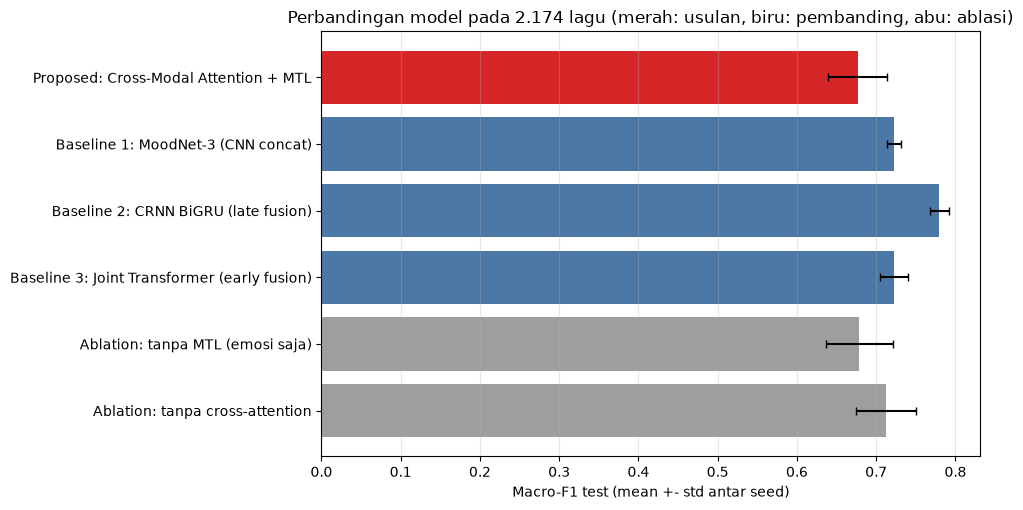

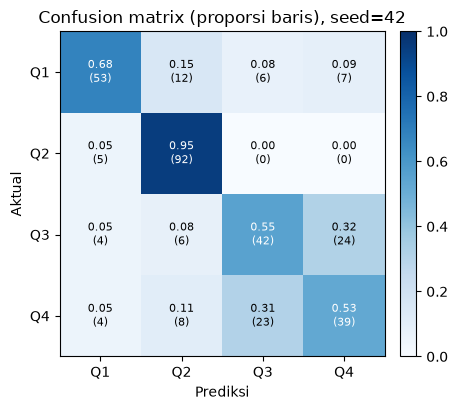

In [14]:
import matplotlib.pyplot as plt

res_df = pd.DataFrame(all_rows)
metric_cols = ["accuracy", "precision_macro", "recall_macro", "macro_f1", "weighted_f1"]
order = list(ALL_EXPERIMENTS.keys())
summary = res_df.groupby("experiment", sort=False)[metric_cols].agg(["mean", "std"]).round(4).loc[order]
res_df.to_csv(EXP / "attn_mtl" / "results_all_runs.csv", index=False)
summary.to_csv(EXP / "attn_mtl" / "results_summary.csv")
display(summary)

gen = (res_df.dropna(subset=["genre_macro_f1"])
       .groupby("experiment", sort=False)[["genre_acc", "genre_macro_f1"]].agg(["mean", "std"]).round(4))
if len(gen):
    print("\nKinerja task genre (hanya model dengan head genre dan lambda > 0):")
    display(gen)

# selisih macro-F1 model usulan terhadap tiap pembanding (per seed, berpasangan)
piv = res_df.pivot(index="seed", columns="experiment", values="macro_f1")
print("\nSelisih macro-F1 (Proposed - model lain), mean +- std antar seed:")
for k in [B1, B2, B3] + ([A1, A2] if RUN_ABLATIONS else []):
    d = piv[P] - piv[k]
    print(f"  vs {k:44s} {d.mean():+.4f} +- {d.std():.4f}  (menang di {(d > 0).sum()}/{len(d)} seed)")

colors = ["#D62728" if n == P else "#4C78A8" if n.startswith("Baseline") else "#9E9E9E" for n in order]
fig, ax = plt.subplots(figsize=(10, 4 + 0.2 * len(order)))
ax.barh(range(len(order)), summary[("macro_f1", "mean")].values,
        xerr=summary[("macro_f1", "std")].values, color=colors, capsize=3)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel("Macro-F1 test (mean +- std antar seed)")
ax.set_title("Perbandingan model pada 2.174 lagu (merah: usulan, biru: pembanding, abu: ablasi)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(EXP / "attn_mtl" / "macro_f1_comparison.png", dpi=160)
plt.show()

yt, yp = preds[(P, SEEDS[0])]
cm = confusion_matrix(yt, yp, labels=list(range(NUM_CLASSES)))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_ORDER); ax.set_yticklabels(CLASS_ORDER)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
ax.set_title(f"Confusion matrix (proporsi baris), seed={SEEDS[0]}")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(EXP / "attn_mtl" / "confusion_proposed.png", dpi=160)
plt.show()


## 11. Analisis interpretabilitas: kontribusi modalitas

Tiga sudut pandang yang saling melengkapi:

1. **Oklusi modalitas** (model-agnostik, dipakai untuk model usulan dan ketiga pembanding): pada data test, input satu modalitas diganti nol (mel = rata-rata train, lirik = semua padding), lalu macro-F1 diukur ulang. Penurunan = seberapa besar model bergantung pada modalitas itu.
2. **Gate fusi** (khusus model usulan): rata-rata nilai gate `g` per sampel = bobot audio (1 - g = bobot lirik), dirangkum per kelas emosi.
3. **Peta cross-attention** (khusus model usulan): bagian lirik yang diperhatikan audio dan segmen audio yang diperhatikan lirik.

Catatan: bobot attention bukan penjelasan kausal yang utuh. Karena itu hasil attention dibaca bersama hasil oklusi, bukan berdiri sendiri.


full         tanpa_audio  \
                                                mean     std        mean   
experiment                                                                 
Proposed: Cross-Modal Attention + MTL         0.6766  0.0376      0.2931   
Baseline 1: MoodNet-3 (CNN concat)            0.7224  0.0090      0.2054   
Baseline 2: CRNN BiGRU (late fusion)          0.7795  0.0119      0.5066   
Baseline 3: Joint Transformer (early fusion)  0.7226  0.0174      0.3670   

                                                     tanpa_lirik          \
                                                 std        mean     std   
experiment                                                                 
Proposed: Cross-Modal Attention + MTL         0.1221      0.3770  0.0884   
Baseline 1: MoodNet-3 (CNN concat)            0.0295      0.0960  0.0007   
Baseline 2: CRNN BiGRU (late fusion)          0.0642      0.5255  0.0512   
Baseline 3: Joint Transformer (early fusion)  0.1424      0.4765  0.0612   

                                             drop_audio         drop_lirik  \
                                                   mean     std       mean   
experiment                                                                   
Proposed: Cross-Modal Attention + MTL            0.3835  0.1456     0.2996   
Baseline 1: MoodNet-3 (CNN concat)               0.5170  0.0343     0.6263   
Baseline 2: CRNN BiGRU (late fusion)             0.2729  0.0761     0.2540   
Baseline 3: Joint Transformer (early fusion)     0.3556  0.1527     0.2461   

                                                     porsi_audio          
                                                 std        mean     std  
experiment                                                                
Proposed: Cross-Modal Attention + MTL         0.0609      0.5501  0.1383  
Baseline 1: MoodNet-3 (CNN concat)            0.0086      0.4519  0.0143  
Baseline 2: CRNN BiGRU (late fusion)          0.0456      0.5142  0.0930  
Baseline 3: Joint Transformer (early fusion)  0.0478      0.5745  0.1426

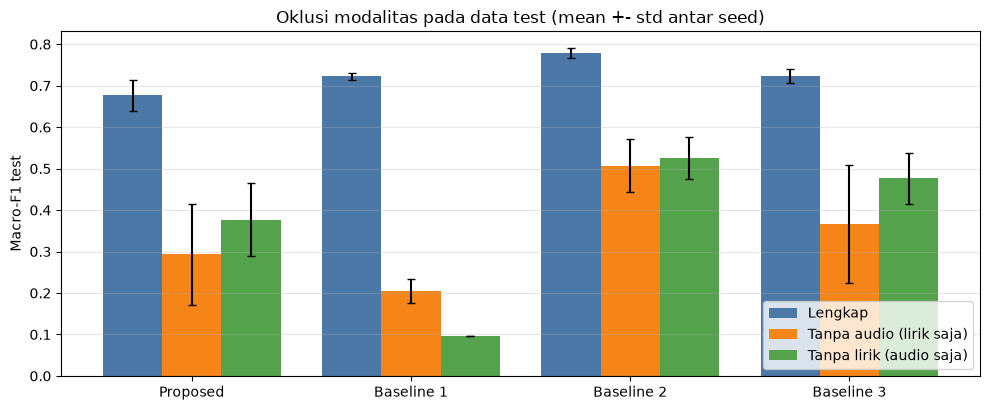

In [15]:
TEST_IX = np.where(MN_MASK & (man.split.values == "test"))[0]
Y_TEST = Y_ALL[TEST_IX]


def load_trained(name, seed):
    m = ALL_EXPERIMENTS[name]["build"]().to(DEVICE)
    m.load_state_dict(torch.load(ckpt_file(name, seed), map_location=DEVICE))
    return m.eval()


@torch.no_grad()
def predict_occ(model, drop=None, bs=16):
    ix = torch.tensor(TEST_IX, device=DEVICE)
    out = []
    for i in range(0, len(ix), bs):
        mel, tok = make_batch(ix[i:i + bs])
        if drop == "audio":
            mel = torch.zeros_like(mel)
        elif drop == "lyrics":
            tok = torch.zeros_like(tok)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(mel, tok)[0].argmax(1).cpu())
    return torch.cat(out).numpy()


def mf1(p):
    return f1_score(Y_TEST, p, average="macro", zero_division=0)


occ_rows = []
for name in MAIN_EXPERIMENTS:
    for seed in SEEDS:
        m = load_trained(name, seed)
        full, no_a, no_l = mf1(predict_occ(m)), mf1(predict_occ(m, "audio")), mf1(predict_occ(m, "lyrics"))
        occ_rows.append(dict(experiment=name, seed=seed, full=full, tanpa_audio=no_a, tanpa_lirik=no_l,
                             drop_audio=full - no_a, drop_lirik=full - no_l))
        del m
        torch.cuda.empty_cache()
occ = pd.DataFrame(occ_rows)
occ["porsi_audio"] = occ.drop_audio.clip(lower=0) / (occ.drop_audio.clip(lower=0) + occ.drop_lirik.clip(lower=0) + 1e-9)
occ_sum = occ.groupby("experiment", sort=False)[
    ["full", "tanpa_audio", "tanpa_lirik", "drop_audio", "drop_lirik", "porsi_audio"]].agg(["mean", "std"]).round(4)
occ.to_csv(EXP / "attn_mtl" / "occlusion_all_runs.csv", index=False)
occ_sum.to_csv(EXP / "attn_mtl" / "occlusion_summary.csv")
display(occ_sum)

names = list(MAIN_EXPERIMENTS.keys())
x = np.arange(len(names)); w = 0.27
g = occ.groupby("experiment", sort=False)
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (col, lab, c) in enumerate([("full", "Lengkap", "#4C78A8"),
                                   ("tanpa_audio", "Tanpa audio (lirik saja)", "#F58518"),
                                   ("tanpa_lirik", "Tanpa lirik (audio saja)", "#54A24B")]):
    ax.bar(x + (k - 1) * w, g[col].mean().loc[names], w, yerr=g[col].std().loc[names],
           label=lab, color=c, capsize=3)
ax.set_xticks(x)
ax.set_xticklabels([n.split(":")[0] for n in names])
ax.set_ylabel("Macro-F1 test")
ax.set_title("Oklusi modalitas pada data test (mean +- std antar seed)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(EXP / "attn_mtl" / "modality_occlusion.png", dpi=160)
plt.show()


,bobot_audio_mean,bobot_audio_std,bobot_lirik_mean
Q1,0.5256,0.0247,0.4744
Q2,0.4914,0.0058,0.5086
Q3,0.5335,0.0098,0.4665
Q4,0.5304,0.0139,0.4696
Semua,0.5183,0.0085,0.4817


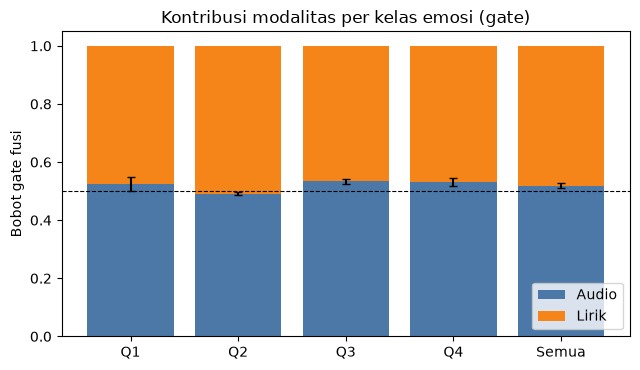

In [16]:
@torch.no_grad()
def collect_internals(model, bs=16):
    ix = torch.tensor(TEST_IX, device=DEVICE)
    gate, a2l, l2a, pred = [], [], [], []
    for i in range(0, len(ix), bs):
        mel, tok = make_batch(ix[i:i + bs])
        with torch.autocast("cuda", dtype=torch.float16):
            emo, _, info = model(mel, tok, return_attn=True)
        gate.append(info["gate"].float().mean(-1).cpu())      # bobot audio per sampel
        a2l.append(info["a2l"].float().cpu())                  # (B,T_audio,100)
        l2a.append(info["l2a"].float().cpu())                  # (B,100,T_audio)
        pred.append(emo.argmax(1).cpu())
    return dict(gate=torch.cat(gate).numpy(), a2l=torch.cat(a2l).numpy(),
                l2a=torch.cat(l2a).numpy(), pred=torch.cat(pred).numpy())


# --- bobot gate per kelas, dirata-rata antar seed
gate_cls = []
internals = {}
for seed in SEEDS:
    m = load_trained(P, seed)
    internals[seed] = collect_internals(m)
    gt_ = internals[seed]["gate"]
    gate_cls.append([gt_[Y_TEST == c].mean() for c in range(NUM_CLASSES)] + [gt_.mean()])
    del m
    torch.cuda.empty_cache()
gate_cls = np.array(gate_cls)
gate_df = pd.DataFrame({"bobot_audio_mean": gate_cls.mean(0), "bobot_audio_std": gate_cls.std(0)},
                       index=CLASS_ORDER + ["Semua"]).round(4)
gate_df["bobot_lirik_mean"] = (1 - gate_df.bobot_audio_mean).round(4)
gate_df.to_csv(EXP / "attn_mtl" / "gate_per_class.csv")
display(gate_df)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
lab = CLASS_ORDER + ["Semua"]
ax.bar(lab, gate_df.bobot_audio_mean, yerr=gate_df.bobot_audio_std, color="#4C78A8", label="Audio", capsize=3)
ax.bar(lab, gate_df.bobot_lirik_mean, bottom=gate_df.bobot_audio_mean, color="#F58518", label="Lirik")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_ylabel("Bobot gate fusi")
ax.set_title("Kontribusi modalitas per kelas emosi (gate)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(EXP / "attn_mtl" / "gate_per_class.png", dpi=160)
plt.show()


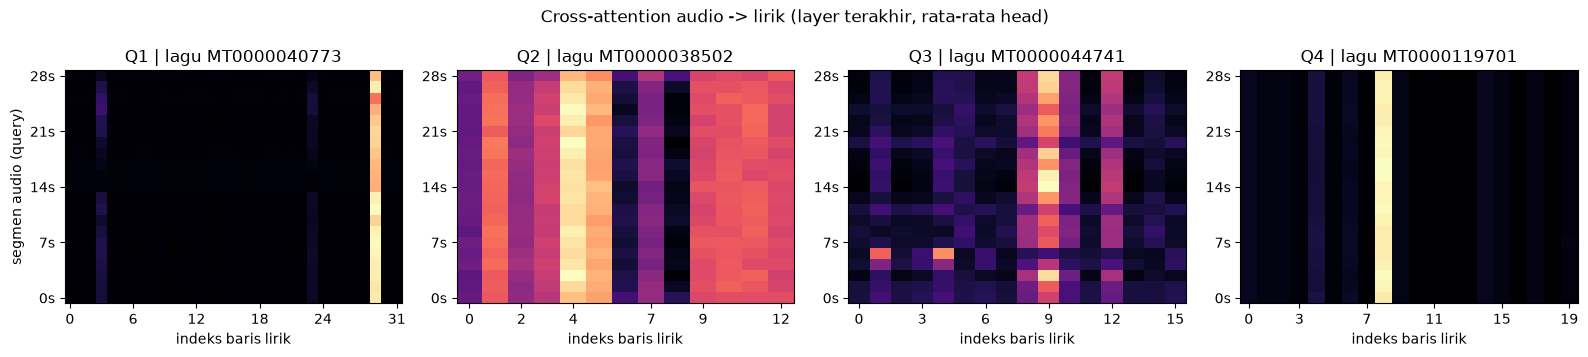

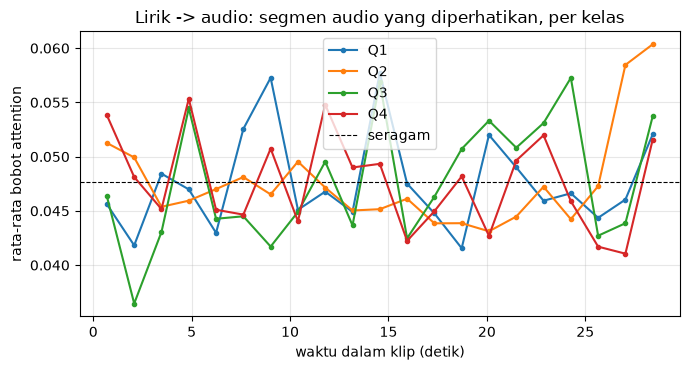

Entropi ternormalisasi attention audio->lirik (rata-rata test): 0.853


In [17]:
# --- peta cross-attention (seed pertama)
seed0 = SEEDS[0]
it = internals[seed0]
T_AUDIO = it["l2a"].shape[2]
SEC = 29.12 / T_AUDIO                      # durasi tiap token audio (detik)
LINE_OK = (TOK[TEST_IX] != 0).any(-1)      # (N_test,100)

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(4 * NUM_CLASSES, 3.6))
for c, ax in enumerate(axes):
    cand = np.where((Y_TEST == c) & (it["pred"] == c))[0]
    k = cand[0] if len(cand) else np.where(Y_TEST == c)[0][0]
    ok = np.where(LINE_OK[k])[0]
    ax.imshow(it["a2l"][k][:, ok], aspect="auto", cmap="magma", origin="lower")
    ax.set_title(f"{CLASS_ORDER[c]} | lagu {man.song_id.values[TEST_IX[k]]}")
    ax.set_xlabel("indeks baris lirik")
    ax.set_xticks(np.linspace(0, len(ok) - 1, min(len(ok), 6)).astype(int))
    ax.set_xticklabels(ok[np.linspace(0, len(ok) - 1, min(len(ok), 6)).astype(int)])
    ax.set_yticks(np.linspace(0, T_AUDIO - 1, 5).astype(int))
    ax.set_yticklabels([f"{t * SEC:.0f}s" for t in np.linspace(0, T_AUDIO - 1, 5).astype(int)])
axes[0].set_ylabel("segmen audio (query)")
fig.suptitle("Cross-attention audio -> lirik (layer terakhir, rata-rata head)")
fig.tight_layout()
fig.savefig(EXP / "attn_mtl" / "cross_attn_audio_to_lyrics.png", dpi=160)
plt.show()

# --- profil temporal: segmen audio mana yang diperhatikan lirik, per kelas
fig, ax = plt.subplots(figsize=(7, 3.8))
t_axis = (np.arange(T_AUDIO) + 0.5) * SEC
for c in range(NUM_CLASSES):
    prof = np.stack([it["l2a"][k][LINE_OK[k]].mean(0)
                     for k in np.where(Y_TEST == c)[0] if LINE_OK[k].any()])
    ax.plot(t_axis, prof.mean(0), marker="o", ms=3, label=CLASS_ORDER[c])
ax.axhline(1 / T_AUDIO, color="k", lw=0.8, ls="--", label="seragam")
ax.set_xlabel("waktu dalam klip (detik)")
ax.set_ylabel("rata-rata bobot attention")
ax.set_title("Lirik -> audio: segmen audio yang diperhatikan, per kelas")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(EXP / "attn_mtl" / "cross_attn_lyrics_to_audio_profile.png", dpi=160)
plt.show()

# --- seberapa terfokus attention (entropi ternormalisasi; 1 = merata, 0 = sangat fokus)
ent = []
for k in range(len(TEST_IX)):
    if LINE_OK[k].any():
        p = it["a2l"][k][:, LINE_OK[k]]
        p = p / p.sum(-1, keepdims=True)
        ent.append((-(p * np.log(p + 1e-12)).sum(-1) / np.log(max(p.shape[1], 2))).mean())
print(f"Entropi ternormalisasi attention audio->lirik (rata-rata test): {np.mean(ent):.3f}")


## Catatan interpretasi

- Pipeline data, split, dan seed identik dengan notebook MoodNet sebelumnya; hanya model dan label genre yang ditambahkan.
- Ketiga pembanding memakai satu task (emosi). Model usulan memakai dua task. Seleksi checkpoint untuk semua model memakai macro-F1 validation emosi, sehingga perbedaan hasil tidak berasal dari kriteria seleksi.
- Dua ablasi memisahkan efek komponen: `tanpa MTL` (lambda = 0) dan `tanpa cross-attention` (encoder dan gated fusion sama, tanpa blok cross-attention). Jika model usulan tidak mengungguli ablasi tersebut, klaim kontribusi komponen terkait perlu direvisi.
- Label genre berasal dari genre utama metadata AllMusic. Kualitasnya bergantung pada distribusi kolom `Genres`; baca distribusi di bagian 6b sebelum menafsirkan manfaat MTL. Nilai `LAMBDA_GENRE` (0,3) belum di-tuning.
- Hanya 3 seed dan satu split, sehingga selisih kecil antar model belum dapat dianggap signifikan secara statistik. Laporkan mean dan std, dan pertimbangkan lebih banyak seed atau cross-validation.
- Oklusi memakai input nol sebagai pengganti modalitas yang dihapus. Itu bukan distribusi data yang pernah dilihat model, jadi penurunan kinerja mencerminkan ketergantungan model, bukan nilai informasi modalitas secara absolut.
- Peta attention hanya menunjukkan indeks baris lirik dan segmen waktu audio. Teks lirik asli tidak dipetakan karena cache GloVe tidak menyimpan vocabulary.
- Memori GPU 6 GB: jika terjadi OOM, turunkan `bs` model usulan dari 16 ke 8 pada `MAIN_EXPERIMENTS`.
